# Filipowicz HMM beads: complete IB and model analyses

Analyzes **HMM_inst** and **HMM_noinst** only. Follows the beads sections of `../main_analyses_figures.ipynb` and `../fit_models.ipynb`: seven-bead histories, NSB information estimates, bootstrap intervals, empirical full and one-back IB bounds and softmax curves, bound classification, information efficiency, psychometrics, three choice models, and paired hazard changes.

Run all cells in order. Full resolution uses the reference analysis settings and can take substantial time. Intermediate results are cached by input content, parameters, and the shared utility source. Original data and notebooks are never overwritten. Smoke mode is for execution checks only; its outputs are kept separate.

In [1]:
from pathlib import Path
import hashlib, importlib.util, json, pickle, os, warnings
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import softmax, xlogy
from scipy.stats import wilcoxon, spearmanr, mannwhitneyu
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'main_analyses_figures.ipynb').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'Filipowicz_beads'
# Explicitly load ROOT utilities: the pilot folder also contains utilities.py.
spec = importlib.util.spec_from_file_location('filipowicz_shared_utils', ROOT / 'utilities.py')
utils = importlib.util.module_from_spec(spec)
import sys
sys.modules[spec.name] = utils
spec.loader.exec_module(utils)

SMOKE = os.environ.get('FILIPOWICZ_SMOKE', '0') == '1'
WSIZE = 7
CI = (2.5, 97.5)
BOOT_ITERS = 20 if SMOKE else 10000
N_B_IB = 12 if SMOKE else 1000
N_B_SOFTMAX = 20 if SMOKE else 10000
IB_ITERLIMIT = 100 if SMOKE else 100000
N_THREADS = min(22, os.cpu_count() or 1)
SEED = 234
THRESHOLD = 0.05
P0 = np.array([[0.5, 0.5]])
E = np.array([[0.8, 0.2], [0.2, 0.8]])
STAY = {'Low': 0.99, 'High': 0.01}  # pilot's generative parameters; hazard = 1 - stay
KEYS = ['Study', 'Subject', 'Session']
OUT = DATA / ('complete_analysis_smoke' if SMOKE else 'complete_analysis_results')
OUT.mkdir(exist_ok=True)
CACHE = OUT / 'cache'
CACHE.mkdir(exist_ok=True)
CONFIG = dict(wsize=WSIZE, ci=CI, boot=BOOT_ITERS, nb=N_B_IB,
              ns=N_B_SOFTMAX, limit=IB_ITERLIMIT, seed=SEED, stay=STAY,
              analysis_version='2026-11-06-v2', utilities=hashlib.sha256((ROOT/'utilities.py').read_bytes()).hexdigest())

def cached(name, signature, fn):
    token = hashlib.sha256(pickle.dumps((CONFIG, signature))).hexdigest()[:20]
    path = CACHE / f'{name}_{token}.pkl'
    if path.exists():
        with path.open('rb') as f: return pickle.load(f)
    value = fn()
    with path.open('wb') as f: pickle.dump(value, f)
    return value

def transition(h):
    return np.array([[h, 1-h], [1-h, h]])

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f'{name}.svg', bbox_inches='tight')
    from IPython.display import SVG
    display(SVG(filename=str(OUT / f'{name}.svg')))
    plt.close(fig)

print('SMOKE CHECK ONLY' if SMOKE else 'Full analysis', CONFIG)


Full analysis {'wsize': 7, 'ci': (2.5, 97.5), 'boot': 10000, 'nb': 1000, 'ns': 10000, 'limit': 100000, 'seed': 234, 'stay': {'Low': 0.99, 'High': 0.01}, 'analysis_version': '2026-11-06-v2', 'utilities': '7a1a710a2cf48eee6d7611500f76bd4a0996bf0e570fff99f8617fd9702c444a'}


## Data checks and trial alignment

Sort within participant/session using `SessTrial`; never form histories across sessions or participants. Bead and jar values are converted from 1/2 to 0/1; choices use `Resp01`, checked against `Resp - 1`.

The reference alignment is retained exactly: a history ending at row t predicts the response at row t+1 and is scored against the jar at row t (`getXY_beads` and `getR_beads`). Thus the first seven responses are dropped and each 500-trial session contributes 493 observations. One-back comparisons use those same observations through `ref_wsize=7`. No response flipping is inferred from performance. The bootstrap resamples aligned trials, as in the reference; its intervals do not account for serial dependence.

In [2]:
raw = pd.concat([pd.read_csv(DATA / f'{study}_beads_finaldat_long.csv')
                 for study in ['HMM_inst', 'HMM_noinst']], ignore_index=True)
assert set(raw.Study) == {'HMM_inst', 'HMM_noinst'}
assert not raw[KEYS + ['SessTrial','Bead','Jar','Resp01']].isna().any().any()
assert not raw.duplicated(KEYS + ['SessTrial']).any()
assert np.array_equal(raw.Resp01, raw.Resp - 1)
for col in ['Bead', 'Jar']:
    assert set(raw[col]) <= {1, 2}
assert set(raw.Resp01) <= {0, 1}
raw = raw.sort_values(KEYS + ['SessTrial']).reset_index(drop=True)
audit = raw.groupby(KEYS).agg(n_trials=('SessTrial','size'), first=('SessTrial','min'),
    last=('SessTrial','max'), sequence_count=('Sequence','nunique'),
    session_order=('Sess_Order','first'))
assert (audit.n_trials == audit['last'] - audit['first'] + 1).all()
assert (audit.sequence_count == 1).all()
assert (raw.groupby(['Study','Subject']).Session.nunique() == 2).all()
display(audit.groupby(level=['Study','Session']).n_trials.agg(['count','min','max']))
audit.to_csv(OUT / 'data_audit.csv')
if SMOKE:
    selected = raw.groupby('Study').Subject.first()
    raw = raw[raw.Subject.isin(selected.values)].copy()

sessions = {}
for key, g in raw.groupby(KEYS, sort=True):
    b = g.Bead.to_numpy(dtype=int) - 1
    j = g.Jar.to_numpy(dtype=int) - 1
    X, Y = utils.getXY_beads(b, j, WSIZE)
    enc, _ = utils.getXY_beads(b, j, WSIZE, encodeX=True)
    X1, Y1 = utils.getXY_beads(b, j, 1, ref_wsize=WSIZE)
    R = utils.getR_beads(g.Resp01.to_numpy(dtype=int), WSIZE)
    if key[2] == 'High':
        R = (1 - R).astype(int)
    assert len(X) == len(R) == len(Y) == len(X1)
    assert np.array_equal(Y, Y1)
    sessions[key] = dict(X=X, X1=X1, enc=enc, Y=Y, R=R,
                         order=int(g.Sess_Order.iloc[0]), sequence=g.Sequence.iloc[0])
print(len(sessions), 'participant sessions')


count  min  max
Study      Session                 
HMM_inst   High        67  500  500
           Low         67  500  500
HMM_noinst High        74  500  500
           Low         74  500  500

282 participant sessions


In [3]:
raw

,Subject,Sequence,Session,Sess_Order,SessTrial,TSCP,TSCP2,Jar,Bead,Resp,Correct_Bead,Correct_Jar,RT,Study,Resp01
0,S10_inst,108,High,1,1,0.0,0,2.0,2.0,2.0,1,1,1301.0,HMM_inst,1.0
1,S10_inst,108,High,1,2,0.0,0,1.0,1.0,1.0,1,1,834.0,HMM_inst,0.0
2,S10_inst,108,High,1,3,0.0,0,2.0,2.0,2.0,1,1,556.0,HMM_inst,1.0
3,S10_inst,108,High,1,4,0.0,0,1.0,1.0,1.0,1,1,464.0,HMM_inst,0.0
4,S10_inst,108,High,1,5,0.0,0,2.0,1.0,2.0,0,1,395.0,HMM_inst,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140995,S9_noinst,17,Low,2,496,71.0,8+,1.0,1.0,1.0,1,1,47.0,HMM_noinst,0.0
140996,S9_noinst,17,Low,2,497,72.0,8+,1.0,2.0,1.0,0,1,117.0,HMM_noinst,0.0
140997,S9_noinst,17,Low,2,498,73.0,8+,1.0,1.0,2.0,0,0,68.0,HMM_noinst,1.0
140998,S9_noinst,17,Low,2,499,74.0,8+,1.0,2.0,1.0,0,1,65.0,HMM_noinst,0.0


In [4]:
sessions[('HMM_inst', 'S10_inst', 'High')]['X']

array([[1, 0, 1, ..., 0, 0, 1],
       [0, 1, 0, ..., 0, 1, 1],
       [1, 0, 0, ..., 1, 1, 1],
       ...,
       [0, 0, 0, ..., 1, 0, 1],
       [0, 0, 1, ..., 0, 1, 0],
       [0, 1, 1, ..., 1, 0, 1]])

In [5]:
sessions[('HMM_inst', 'S10_inst', 'High')]['Y']

array([1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,

In [6]:
sessions[('HMM_inst', 'S10_inst', 'High')]['R']

array([1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1,

In [7]:
key = ('HMM_inst', 'S10_inst', 'High')
s = sessions[key]
X, X1, R = s['X'], s['X1'], s['R']
H = transition(STAY[key[2]])
posts = {'oneback': utils.P_jar_g_beads(X1, E, H, P0),
         'opt': utils.P_jar_g_beads(X, E, H, P0)}

In [8]:
posts['opt']

array([[0.00742253, 0.99257747],
       [0.92438862, 0.07561138],
       [0.03324141, 0.96675859],
       [0.97811043, 0.02188957],
       [0.23089125, 0.76910875],
       [0.96675859, 0.03324141],
       [0.02188957, 0.97811043],
       [0.98158267, 0.01841733],
       [0.06742662, 0.93257338],
       [0.96909977, 0.03090023],
       [0.02081706, 0.97918294],
       [0.99491375, 0.00508625],
       [0.06742662, 0.93257338],
       [0.96909977, 0.03090023],
       [0.25381704, 0.74618296],
       [0.58766834, 0.41233166],
       [0.26209189, 0.73790811],
       [0.79518748, 0.20481252],
       [0.16494468, 0.83505532],
       [0.98164917, 0.01835083],
       [0.01557717, 0.98442283],
       [0.99572652, 0.00427348],
       [0.05197891, 0.94802109],
       [0.78673563, 0.21326437],
       [0.07538618, 0.92461382],
       [0.96687074, 0.03312926],
       [0.02181024, 0.97818976],
       [0.98164917, 0.01835083],
       [0.01557717, 0.98442283],
       [0.99572652, 0.00427348],
       [0.

## Empirical and theoretical bounds

Each empirical bound applies the generatively optimal encoder to that session's observed bead/jar sequence, following `get_IB_bound_emp`. Identical sequences share cached results. Both full and one-back encoders use the seven-bead analysis sample. Plotted population summaries are labeled; efficiency and classification always use each participant's own empirical bound. Theoretical bounds provide a common visual reference, while empirical curves can vary across sequences.

The IB solver depends only on the generative process, not the observed sequence. To avoid repeating identical optimizations, solve each hazard/encoder once with the same grid, seeds, and initializations, then evaluate all encoders on each session and apply the reference upper-envelope routine. Empirical information and softmax curves are computed by aggregating identical histories, which is algebraically equivalent to the trial-wise reference calculation. Assertions compare the accelerated evaluation with the shared utilities.

In [9]:
def envelope(curve):
    ub, inds = utils.compute_upper_bound(curve['I_XR'], curve['I_RY'])
    return dict(I_XR=np.atleast_1d(ub[:,0]), I_RY=np.atleast_1d(ub[:,1]))

# Keep the entire beta grid until AFTER evaluation on empirical sequences.
encoders, theory = {}, {}
for hazard in STAY:
    for label,size in [('full',WSIZE),('1back',1)]:
        likelihood=utils.P_beads_g_jar(utils.get_beads_Xset(size),E,transition(STAY[hazard]))
        curve=cached('encoder_grid', (hazard,label),
            lambda likelihood=likelihood:utils.get_IB_bound(likelihood,P0,
                N_b=N_B_IB,max_b=50,iterlimit=IB_ITERLIMIT,N_threads=N_THREADS,
                enforce_monotonic=False))
        encoders[hazard,label]=curve['p_RgX']
        theory[hazard,label]=envelope(curve)
        print('Solved generative encoders:',hazard,label,flush=True)

def empirical_curve(policies, X, Y, Xset):
    # policies: beta x history x response; use counts rather than repeated trial arrays.
    lookup={tuple(x):i for i,x in enumerate(Xset)}
    inds=np.array([lookup[tuple(x)] for x in X])
    counts=np.zeros((len(Xset),2))
    np.add.at(counts,(inds,Y),1)
    joint=counts/len(Y)
    px=joint.sum(axis=1)
    py=joint.sum(axis=0)
    pr=np.einsum('bxr,x->br',policies,px)
    pyr=np.einsum('bxr,xy->byr',policies,joint)
    with np.errstate(divide='ignore',invalid='ignore'):
        ix=np.sum(px[None,:,None]*xlogy(policies,policies/pr[:,None,:]),axis=(1,2))/np.log(2)
        iy=np.sum(xlogy(pyr,pyr/(py[None,:,None]*pr[:,None,:])),axis=(1,2))/np.log(2)
    # Direct trial-wise reference check at the first beta.
    assert np.allclose(ix[0],utils.compute_I_XR_emp(policies[0,inds]),atol=1e-10)
    assert np.allclose(iy[0],utils.compute_I_RY_emp(policies[0,inds],Y),atol=1e-10)
    return dict(I_XR=ix,I_RY=iy)

def make_bounds(s,hazard):
    result={}
    for label,X,size in [('full',s['X'],WSIZE),('1back',s['X1'],1)]:
        Xset=utils.get_beads_Xset(size)
        result[label]=envelope(empirical_curve(encoders[hazard,label],X,s['Y'],Xset))
        post=utils.P_jar_g_beads(Xset,E,transition(STAY[hazard]),P0)
        beta=np.linspace(50/N_B_SOFTMAX,50,N_B_SOFTMAX)
        policies=softmax(beta[:,None,None]*post[None,:,:],axis=2)
        result[label+'_softmax']=empirical_curve(policies,X,s['Y'],Xset)
    return result

bounds={}
for i,(key,s) in enumerate(sessions.items()):
    bounds[key]=cached('bounds_aggregated_v1',(key[2],s['X'],s['Y']),
        lambda s=s,key=key:make_bounds(s,key[2]))
    if (i+1)%20==0: print('Empirical bounds:',i+1,'/',len(sessions),flush=True)


Solved generative encoders: Low full
Solved generative encoders: Low 1back
Solved generative encoders: High full
Solved generative encoders: High 1back
Empirical bounds: 20 / 282
Empirical bounds: 40 / 282
Empirical bounds: 60 / 282
Empirical bounds: 80 / 282
Empirical bounds: 100 / 282
Empirical bounds: 120 / 282
Empirical bounds: 140 / 282
Empirical bounds: 160 / 282
Empirical bounds: 180 / 282
Empirical bounds: 200 / 282
Empirical bounds: 220 / 282
Empirical bounds: 240 / 282
Empirical bounds: 260 / 282
Empirical bounds: 280 / 282


## Participant information measures

Information is in bits. Efficiency is I(R;Y) divided by the session's full empirical bound at its estimated I(X;R); intervals divide the I(R;Y) bootstrap limits by the same denominator and do not include bound or I(X;R) uncertainty. Values above one are retained. Interpolation follows the reference, including endpoint saturation; out-of-range observations are flagged for inspection. The 0.05-bit filter is reported separately from the complete sample.

The binary bootstrap uses `filipowicz_analysis_helpers.py` to cache NSB entropies by joint counts. It draws the identical trial indices for every reference seed and returns the same percentile intervals. A persistent fork-based worker pool retains count caches across sessions (Linux execution environment).

In [55]:
helper_spec = importlib.util.spec_from_file_location('filipowicz_analysis_helpers', DATA/'filipowicz_analysis_helpers.py')
helpers = importlib.util.module_from_spec(helper_spec)
sys.modules[helper_spec.name] = helpers
helper_spec.loader.exec_module(helpers)
import multiprocessing as mp
# Persistent workers retain entropy-count caches across participant sessions.
BOOT_POOL = mp.get_context('fork').Pool(N_THREADS)

def measure(key, s):
    R, Y = s['R'], s['Y']
    ix = utils.mutual_inf_nsb(s['enc'], R, [2**WSIZE, 2])
    iy = utils.mutual_inf_nsb(R, Y, [2, 2])
    lo, hi = helpers.bootstrap_ci(R, Y, CI, BOOT_ITERS, seed=SEED, pool=BOOT_POOL, chunks=N_THREADS)
    bound = bounds[key]['full']
    denom = np.interp(ix, bound['I_XR'], bound['I_RY'])
    classification = utils.classify_by_bound(np.array([ix]), np.array([iy]),
        np.array([lo]), np.array([hi]), [bound, bounds[key]['1back']], ['full','1back'])[0]
    return dict(zip(KEYS, key), n_trials=len(R), session_order=s['order'],
        Ixr=ix, Iry=iy, Iry_CI_lower=lo, Iry_CI_upper=hi,
        info_efficiency=iy/denom if denom > 1e-12 else np.nan,
        info_efficiency_CI_lower=lo/denom if denom > 1e-12 else np.nan,
        info_efficiency_CI_upper=hi/denom if denom > 1e-12 else np.nan,
        bound_class=classification, below_threshold=ix < THRESHOLD,
        outside_bound_range=ix < np.min(bound['I_XR']) or ix > np.max(bound['I_XR']),
        aligned_jar_accuracy=np.mean(R == Y))

ibdf = pd.DataFrame([cached('measures_verified', (key, s), lambda key=key,s=s: measure(key,s))
                     for key,s in sessions.items()])
BOOT_POOL.close()
BOOT_POOL.join()
ibdf.to_csv(OUT / 'participant_IB_measures.csv', index=False)
display(ibdf.groupby(['Study','Session'])[['Ixr','Iry','info_efficiency','aligned_jar_accuracy']].agg(['median','mean']))
display(pd.crosstab([ibdf.Study, ibdf.Session], ibdf.bound_class))


Ixr                 Iry           info_efficiency  \
                      median      mean    median      mean          median   
Study      Session                                                           
HMM_inst   High     0.147996  0.273805  0.076146  0.141344        0.553533   
           Low      0.379610  0.391921  0.232428  0.239317        0.791330   
HMM_noinst High     0.264310  0.315931  0.103962  0.172158        0.513145   
           Low      0.464412  0.461932  0.235835  0.275304        0.866952   

                             aligned_jar_accuracy            
                        mean               median      mean  
Study      Session                                           
HMM_inst   High     0.673581             0.604462  0.624716  
           Low      0.788232             0.797160  0.753323  
HMM_noinst High     0.547942             0.679513  0.649005  
           Low      0.836702             0.809331  0.803931

bound_class         1back  full  none
Study      Session                   
HMM_inst   High        28    16    23
           Low         23    36     8
HMM_noinst High        37    20    17
           Low         20    38    16

## Choice model fits

The models are identical in form to the beads models in `fit_models.ipynb`: softmax(β* × posterior jar probability), with β* ≥ 0. The optimal and one-back models have one parameter and the correct session transition matrix. The subjective-stay model has β* and h ∈ [0,1], with 25 initializations: β* = {0.1,1,3,5,8}, h = {0.6,0.7,0.8,0.9,0.99}. This retains the reference `eps=1e-19` option, even though that very small finite-difference step may impair optimization; success flags and messages are exported for inspection. BIC = k log(n) + 2 NLL; ties follow the reference priority one-back, optimal, subjective h.

Likelihood is evaluated with a stable log-softmax equivalent, also supporting participants who use only one response. Relative entropy is the reference trial-averaged empirical-to-model KL in nats. Models are fit to every session, before any information-based filtering. These are in-sample model comparisons, not cross-validated predictions.

In [56]:
from scipy.special import log_softmax

def fit_session(key, s):
    X, X1, R = s['X'], s['X1'], s['R']
    H = transition(STAY[key[2]])
    posts = {'oneback': utils.P_jar_g_beads(X1, E, H, P0),
             'opt': utils.P_jar_g_beads(X, E, H, P0)}
    def logits(label, params):
        post = (utils.P_jar_g_beads(X, E, transition(params[1]), P0)
                if label == 'fullparam' else posts[label])
        return params[0] * post
    # Always construct two empirical response columns, including constant responders.
    empirical = np.zeros((len(R), 2))
    for value in np.unique(s['enc']):
        mask = s['enc'] == value
        empirical[mask] = np.eye(2)[R[mask]].mean(axis=0)
    row = dict(zip(KEYS,key), n_trials=len(R))
    fits = {}
    for label in ['oneback', 'opt', 'fullparam']:
        obj = lambda params: -log_softmax(logits(label, params), axis=1)[np.arange(len(R)),R].sum()
        if label == 'fullparam':
            results = [minimize(obj, np.array([b,h]), bounds=[(0,None),(0,1)],
                                options={'eps':1e-19})
                       for b,h in product([0.1,1.,3.,5.,8.], [0.6,0.7,0.8,0.9,0.99])]
            # <= in the reference makes the last equal-loss result win.
            finite = [r for r in results if np.isfinite(r.fun)]
            if not finite: raise RuntimeError(f'All fits failed: {key}')
            result = min(reversed(finite), key=lambda r:r.fun)
            row['fullparam_h'] = result.x[1]
            row['fullparam_successful_starts'] = sum(r.success for r in results)
        else:
            result = minimize(obj, np.array([1.]), bounds=[(0,None)])
        fits[label] = result
        lp = log_softmax(logits(label,result.x), axis=1)
        row.update({f'{label}_betastar':result.x[0], f'{label}_loss':result.fun,
            f'{label}_BIC':utils.compute_BIC(2 if label=='fullparam' else 1,len(R),result.fun),
            f'{label}_rel_entropy':np.sum(xlogy(empirical,empirical) - empirical*lp)/len(R),
            f'{label}_success':bool(result.success), f'{label}_message':str(result.message)})
    best = min(['oneback','opt','fullparam'], key=lambda label:row[f'{label}_BIC'])
    row['best_model'] = {'opt':'fully_optimal'}.get(best,best)
    for field in ['betastar','loss','BIC','rel_entropy']:
        row['best_model_'+field] = row[best+'_'+field]
    return row

model_rows = []
for i,(key,s) in enumerate(sessions.items()):
    model_rows.append(cached('fits_v1', (key,s), lambda key=key,s=s:fit_session(key,s)))
    if (i+1)%20 == 0: print('Fitted',i+1,'/',len(sessions),flush=True)
modeldf = pd.DataFrame(model_rows)
modeldf.to_csv(OUT / 'model_fits.csv',index=False)
alldata = ibdf.merge(modeldf.drop(columns='n_trials'),on=KEYS,validate='one_to_one')
alldata.to_csv(OUT / 'all_participant_analysis.csv',index=False)
display(modeldf.groupby(['Study','Session'])[['oneback_success','opt_success','fullparam_success']].mean())
display(pd.crosstab([alldata.Study,alldata.Session],alldata.best_model))


Fitted 20 / 282
Fitted 40 / 282
Fitted 60 / 282
Fitted 80 / 282
Fitted 100 / 282
Fitted 120 / 282
Fitted 140 / 282
Fitted 160 / 282
Fitted 180 / 282
Fitted 200 / 282
Fitted 220 / 282
Fitted 240 / 282
Fitted 260 / 282
Fitted 280 / 282


oneback_success  opt_success  fullparam_success
Study      Session                                                 
HMM_inst   High                 1.0          1.0                1.0
           Low                  1.0          1.0                1.0
HMM_noinst High                 1.0          1.0                1.0
           Low                  1.0          1.0                1.0

best_model          fullparam  fully_optimal  oneback
Study      Session                                   
HMM_inst   High            20             17       30
           Low             35             17       15
HMM_noinst High            19             25       30
           Low             40             24       10

## IB plots and model comparisons

Faint curves show the distinct empirical sequence bounds; black curves show the theoretical bounds. Separate panels preserve instruction group and hazard. Error bars draw the actual percentile interval, even when the point estimate lies outside it. A second plot colors participants by the two-model and three-model BIC decisions.

In [57]:
alldata

,Study,Subject,Session,n_trials,session_order,Ixr,Iry,Iry_CI_lower,Iry_CI_upper,info_efficiency,...,fullparam_loss,fullparam_BIC,fullparam_rel_entropy,fullparam_success,fullparam_message,best_model,best_model_betastar,best_model_loss,best_model_BIC,best_model_rel_entropy
0,HMM_inst,S10_inst,High,493,1,0.628236,0.259417,0.195027,0.332392,0.603882,...,122.488188,257.377393,1.002393e-01,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,fullparam,4.264262,1.224882e+02,257.377393,1.002393e-01
1,HMM_inst,S10_inst,Low,493,1,0.734254,0.566221,0.487628,0.654350,1.131658,...,97.106064,206.613146,1.077558e-01,True,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,fullparam,3.946390,9.710606e+01,206.613146,1.077558e-01
2,HMM_inst,S11_inst,High,493,1,0.751527,0.219615,0.158659,0.289256,0.386430,...,70.575276,153.551571,5.882632e-02,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,oneback,5.658214,7.058424e+01,147.368983,5.884450e-02
3,HMM_inst,S11_inst,Low,493,1,0.344220,0.249875,0.184894,0.322858,0.976883,...,189.385490,391.171999,1.135017e-01,True,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,fully_optimal,2.200425,1.912874e+02,388.775260,1.173595e-01
4,HMM_inst,S12_inst,High,493,2,0.076417,0.029000,0.009009,0.060836,0.450427,...,315.747761,643.896540,1.287014e-01,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,oneback,1.084742,3.169372e+02,640.074991,1.311142e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277,HMM_noinst,S7_noinst,Low,493,1,0.660923,0.204734,0.145933,0.273536,0.371067,...,86.784840,185.970699,5.175853e-02,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,oneback,5.187427,8.682197e+01,179.844450,5.183385e-02
278,HMM_noinst,S8_noinst,High,493,1,0.044725,-0.000787,-0.002202,0.010557,-0.021136,...,341.721560,695.844138,2.051382e-01,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,oneback,0.000000,3.417216e+02,689.643629,2.051382e-01
279,HMM_noinst,S8_noinst,Low,493,1,0.066742,0.044473,0.018126,0.081644,0.804840,...,320.649290,653.699598,1.399310e-01,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,oneback,0.951315,3.224332e+02,651.066848,1.435494e-01
280,HMM_noinst,S9_noinst,High,493,2,0.751330,0.217987,0.159146,0.287321,0.447853,...,69.478318,151.357654,4.980073e-02,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,oneback,5.658213,7.058424e+01,147.368983,5.204397e-02


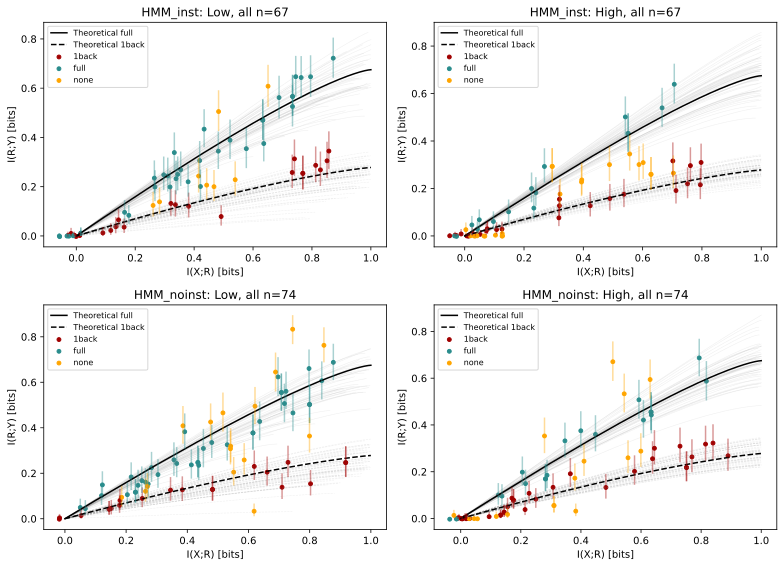

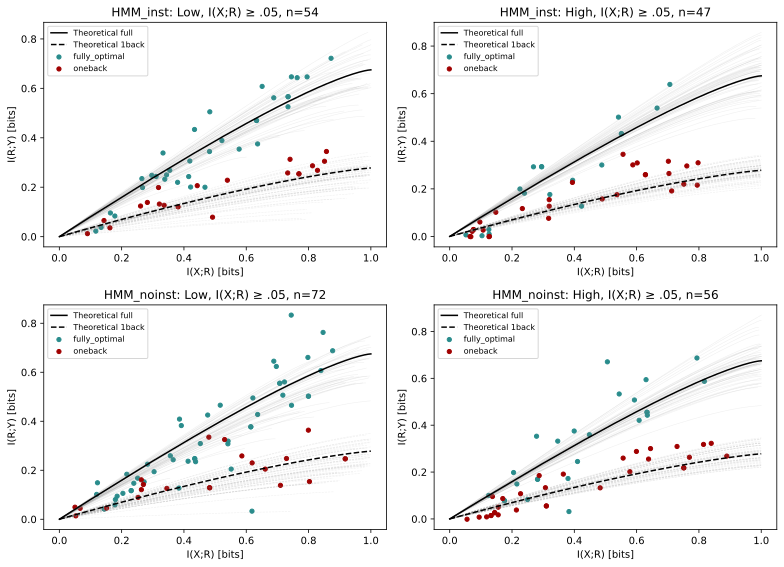

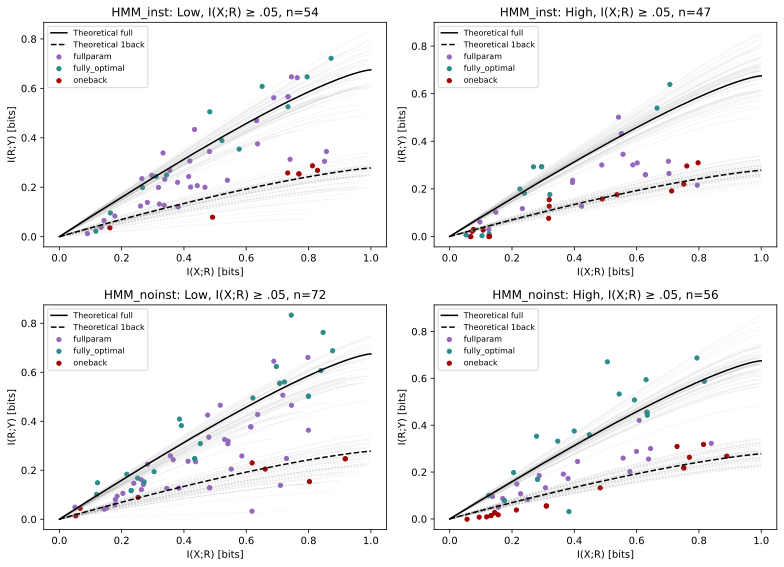

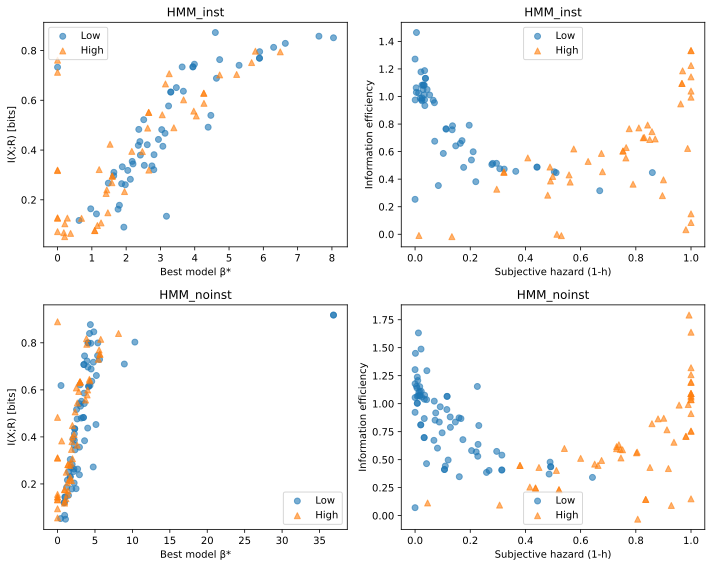

In [ ]:
COLORS = {'full':'#298C8C','1back':'#A00000','none':'orange',
          'fully_optimal':'#298C8C','oneback':'#A00000','fullparam':'#9467bd'}

def draw_bounds(ax, study, hazard):
    seen = set()
    for key in bounds:
        if key[0] != study or key[2] != hazard: continue
        s = sessions[key]
        token = hashlib.sha256(s['X'].tobytes()+s['Y'].tobytes()).hexdigest()
        if token in seen: continue
        seen.add(token)
        for label, style in [('full','-'),('1back','--')]:
            b=bounds[key][label]
            ax.plot(b['I_XR'],b['I_RY'],style,color='gray',alpha=.12,lw=.6)
    for label,style in [('full','-'),('1back','--')]:
        b=theory[hazard,label]
        ax.plot(b['I_XR'],b['I_RY'],style,color='black',label='Theoretical '+label)
    ax.set(xlabel='I(X;R) [bits]',ylabel='I(R;Y) [bits]')

fig, axes=plt.subplots(2,2,figsize=(11,8))
for i,study in enumerate(['HMM_inst','HMM_noinst']):
    for j,hazard in enumerate(['Low','High']):
        ax=axes[i,j]; draw_bounds(ax,study,hazard)
        d=alldata[(alldata.Study==study)&(alldata.Session==hazard)]
        for label,g in d.groupby('bound_class'):
            ax.vlines(g.Ixr,g.Iry_CI_lower,g.Iry_CI_upper,color=COLORS[label],alpha=.4)
            ax.scatter(g.Ixr,g.Iry,c=COLORS[label],s=15,label=label)
        ax.set_title(f'{study}: {hazard}, all n={len(d)}'); ax.legend(fontsize=8)
savefig(fig,'IB_bound_classification')

for comparison in ['two_model','three_model']:
    fig,axes=plt.subplots(2,2,figsize=(11,8))
    for i,study in enumerate(['HMM_inst','HMM_noinst']):
        for j,hazard in enumerate(['Low','High']):
            ax=axes[i,j];draw_bounds(ax,study,hazard)
            d=alldata[(alldata.Study==study)&(alldata.Session==hazard)&(~alldata.below_threshold)].copy()
            d['label']=(np.where(d.opt_BIC < d.oneback_BIC,'fully_optimal','oneback')
                        if comparison=='two_model' else d.best_model)
            for label,g in d.groupby('label'):
                ax.scatter(g.Ixr,g.Iry,c=COLORS[label],s=18,label=label)
            ax.set_title(f'{study}: {hazard}, I(X;R) ≥ .05, n={len(d)}');ax.legend(fontsize=8)
    savefig(fig,'IB_'+comparison)

fig,axes=plt.subplots(2,2,figsize=(10,8))
for i,study in enumerate(['HMM_inst','HMM_noinst']):
    for hazard,marker in [('Low','o'),('High','^')]:
        d=alldata[(alldata.Study==study)&(alldata.Session==hazard)&(~alldata.below_threshold)]
        axes[i,0].scatter(d.best_model_betastar,d.Ixr,marker=marker,label=hazard,alpha=.6)
        axes[i,1].scatter(1-d.fullparam_h,d.info_efficiency,marker=marker,label=hazard,alpha=.6)
    axes[i,0].set(xlabel='Best model β*',ylabel='I(X;R) [bits]',title=study)
    axes[i,1].set(xlabel='Subjective hazard (1-h)',ylabel='Information efficiency',title=study)
    for ax in axes[i]: ax.legend()
savefig(fig,'model_parameters_and_efficiency')


## Paired low → high hazard changes

Every arrow pairs by **Study + Subject**, never by row position. Show both all participants and the reference arrow inclusion rule (I(X;R) ≥ .05 in at least one condition). Paired efficiency tests additionally require ≥ .05 in both conditions. Low and high have different generative bounds, so each condition's own bound is used for efficiency. These are hazard contrasts, not learning contrasts. Session order is retained for sensitivity summaries.

Arrow and change panels use the reference direction-based orange–blue colors, black-edged arrows, and white triangular median marker. Only the **low-hazard full and one-back bounds** are displayed in the arrow panels; efficiency calculations continue to use each condition’s own bound.

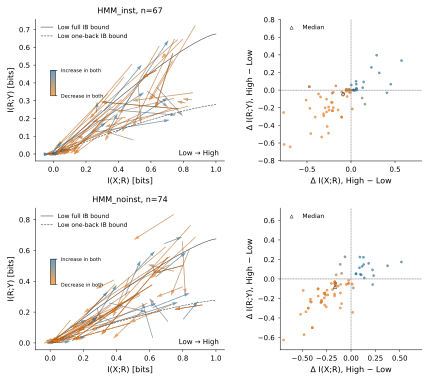

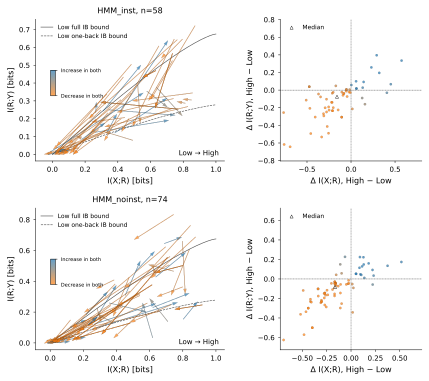

,Study,sample,metric,n,median_change,mean_change,n_increase,p_value,p_holm
0,HMM_inst,all,Ixr,67,-0.091256,-0.118116,22,5.025086e-04,1.005017e-03
1,HMM_inst,all,Iry,67,-0.038440,-0.097973,23,2.578611e-04,7.735832e-04
2,HMM_inst,all,info_efficiency,54,-0.282382,-0.105557,20,2.473638e-03,2.473638e-03
3,HMM_inst,all,aligned_jar_accuracy,67,-0.087221,-0.128606,16,1.466276e-07,7.331381e-07
4,HMM_inst,all,fullparam_h,67,-0.577181,-0.477554,11,1.936030e-09,1.161618e-08
5,HMM_inst,all,best_model_betastar,67,-0.925959,-1.118556,16,3.687480e-05,1.474992e-04
6,HMM_inst,reference_filter,Ixr,58,-0.159332,-0.140227,15,2.778870e-04,5.557740e-04
7,HMM_inst,reference_filter,Iry,58,-0.074875,-0.114461,17,1.135643e-04,3.406928e-04
8,HMM_inst,reference_filter,info_efficiency,43,-0.191536,-0.200065,17,5.852152e-03,5.852152e-03
9,HMM_inst,reference_filter,aligned_jar_accuracy,58,-0.109533,-0.141498,14,6.802431e-07,3.401215e-06


delta_Ixr           delta_Iry            \
                                 count    median     count    median   
Study      low_session_order                                           
HMM_inst   1                        30 -0.072899        30 -0.027402   
           2                        37 -0.146177        37 -0.038440   
HMM_noinst 1                        36 -0.120894        36 -0.057814   
           2                        38 -0.168780        38 -0.101736   

                             delta_info_efficiency            
                                             count    median  
Study      low_session_order                                  
HMM_inst   1                                    23 -0.164616  
           2                                    31 -0.299060  
HMM_noinst 1                                    31 -0.147881  
           2                                    35 -0.185081

best_model                      fullparam  fully_optimal  oneback
Study      Session bound_class                                   
HMM_inst   High    1back                4              5       19
                   full                 6              7        3
                   none                10              5        8
           Low     1back                9              3       11
                   full                20             12        4
                   none                 6              2        0
HMM_noinst High    1back               10              5       22
                   full                 4             15        1
                   none                 5              5        7
           Low     1back               11              0        9
                   full                17             20        1
                   none                12              4        0

In [59]:
metrics=['Ixr','Iry','info_efficiency','aligned_jar_accuracy','fullparam_h','best_model_betastar']
paired=alldata.pivot(index=['Study','Subject'],columns='Session',values=metrics)
assert not paired[[('Ixr','Low'),('Ixr','High')]].isna().any().any()
keep_any=paired['Ixr'].max(axis=1)>=THRESHOLD
keep_both=paired['Ixr'].min(axis=1)>=THRESHOLD
changes=pd.DataFrame(index=paired.index)
for metric in metrics:
    changes['delta_'+metric]=paired[(metric,'High')]-paired[(metric,'Low')]
changes['include_any']=keep_any
changes['include_both']=keep_both
changes.to_csv(OUT/'paired_hazard_changes.csv')

# Same direction-to-color mapping and arrow geometry as reference cells 63/65/69.
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
change_cmap = LinearSegmentedColormap.from_list('hazard_change',
    [plt.get_cmap('tab10')(1), plt.get_cmap('tab10')(0)])
change_norm = Normalize(vmin=-1, vmax=1)

def change_color(delta_x, delta_y):
    theta = np.cos(np.arctan2(delta_x, delta_y) - np.pi/4)
    return change_cmap(change_norm(theta))

def format_change_axis(ax):
    ax.tick_params(axis='both', labelsize=7, width=.5, length=2)
    for side in ['top','right']: ax.spines[side].set_visible(False)
    for side in ['bottom','left']: ax.spines[side].set_linewidth(.5)
    ax.xaxis.label.set_size(8); ax.yaxis.label.set_size(8)

for filtered in [False,True]:
    fig,axes=plt.subplots(2,2,figsize=(6.4,5.4),dpi=300)
    for i,study in enumerate(['HMM_inst','HMM_noinst']):
        p=paired.loc[study]
        if filtered: p=p[keep_any.loc[study]]
        ax=axes[i,0]
        for label,style,title in [('full','-','Low full IB bound'),
                                  ('1back','--','Low one-back IB bound')]:
            bound=theory['Low',label]
            ax.plot(bound['I_XR'],bound['I_RY'],style,color='black',
                    linewidth=.6,alpha=.7,label=title)
        dx=p['Ixr']['High']-p['Ixr']['Low'];dy=p['Iry']['High']-p['Iry']['Low']
        for subject,r in p.iterrows():
            color=change_color(dx.loc[subject],dy.loc[subject])
            ax.annotate('',xy=(r['Ixr','High'],r['Iry','High']),
                xytext=(r['Ixr','Low'],r['Iry','Low']),
                arrowprops=dict(facecolor=color,edgecolor='black',alpha=.7,
                    linewidth=.1,width=.5,headwidth=3,headlength=5))
            axes[i,1].scatter(dx.loc[subject],dy.loc[subject],color=color,
                s=6,edgecolors='black',alpha=.7,linewidth=.1,zorder=2)
        # Annotations do not autoscale: include every arrow endpoint explicitly.
        ax.update_datalim(np.column_stack([
            np.r_[p['Ixr']['Low'],p['Ixr']['High']],
            np.r_[p['Iry']['Low'],p['Iry']['High']]]))
        ax.autoscale_view()
        ax.annotate('Low → High',xy=(.97,.03),xycoords='axes fraction',
                    fontsize=7,ha='right',va='bottom')
        ax.set(xlabel='I(X;R) [bits]',ylabel='I(R;Y) [bits]')
        ax.set_title(f'{study}, n={len(p)}',fontsize=8)
        ax.legend(fontsize=6,frameon=False,loc='upper left')
        # The reference color scale: orange decreases in both, blue increases in both.
        color_ax=ax.inset_axes([.08,.46,.025,.18])
        cbar=fig.colorbar(ScalarMappable(norm=Normalize(0,1),cmap=change_cmap),
                          cax=color_ax,orientation='vertical',alpha=.7)
        cbar.set_ticks([0,1],labels=['Decrease in both','Increase in both'])
        cbar.ax.tick_params(labelsize=5,width=.5,length=2)
        cbar.outline.set_linewidth(.5)
        delta_ax=axes[i,1]
        delta_ax.axhline(0,color='black',linewidth=.3,linestyle='--',zorder=1)
        delta_ax.axvline(0,color='black',linewidth=.3,linestyle='--',zorder=1)
        if len(p):
            delta_ax.scatter(np.median(dx),np.median(dy),color='white',
                edgecolors='black',marker='^',s=10,linewidth=.4,zorder=5,
                clip_on=False,label='Median')
            delta_ax.legend(fontsize=6,frameon=False,loc='upper left')
        delta_limit=max(.45,1.05*np.max(np.abs(np.r_[dx,dy]))) if len(p) else .45
        delta_ax.set(xlim=(-delta_limit,delta_limit),ylim=(-delta_limit,delta_limit),
                     xlabel='Δ I(X;R), High − Low',ylabel='Δ I(R;Y), High − Low')
        delta_ax.set_aspect('equal',adjustable='box')
        for panel in axes[i]: format_change_axis(panel)
    savefig(fig,'hazard_arrows_'+('reference_filter' if filtered else 'all'))

stats=[]
for study in ['HMM_inst','HMM_noinst']:
    for sample in ['all','reference_filter']:
        for metric in metrics:
            p=paired.loc[study]
            if sample=='reference_filter':
                p=p[(keep_both if metric=='info_efficiency' else keep_any).loc[study]]
            delta=(p[(metric,'High')]-p[(metric,'Low')]).dropna().to_numpy()
            test=wilcoxon(delta) if len(delta) and np.any(delta!=0) else None
            stats.append(dict(Study=study,sample=sample,metric=metric,n=len(delta),
                median_change=np.median(delta) if len(delta) else np.nan,
                mean_change=np.mean(delta) if len(delta) else np.nan,
                n_increase=int((delta>0).sum()),p_value=test.pvalue if test else 1.0))
stats=pd.DataFrame(stats)
# Holm correction within each study/sample family.
def holm(p):
    p=np.asarray(p);order=np.argsort(p);out=np.empty(len(p))
    out[order]=np.minimum(1,np.maximum.accumulate(p[order]*(len(p)-np.arange(len(p)))))
    return out
stats['p_holm']=stats.groupby(['Study','sample']).p_value.transform(holm)
stats.to_csv(OUT/'paired_statistics.csv',index=False)
display(stats)
# Order sensitivity: was Low first or second?
order=alldata[alldata.Session=='Low'].set_index(['Study','Subject']).session_order
changes['low_session_order']=order
display(changes.groupby(['Study','low_session_order'])[['delta_Ixr','delta_Iry','delta_info_efficiency']].agg(['count','median']))
display(pd.crosstab([alldata.Study,alldata.Session,alldata.bound_class],alldata.best_model))


## Example participant psychometrics and IB locations

Each point pools responses for one **unique seven-bead sequence**, separately for each participant and hazard condition. Sequences with the same posterior remain separate points. Both strategy panels retain the same sequence groups; the full strategy uses the seven-bead posterior and the one-back strategy uses the final bead's posterior. As in the reference notebook, opacity is proportional to sequence count, and the dashed prediction is the softmax psychometric curve whose β* is interpolated at the participant's measured I(X;R). The reference plotting and divergence utilities are used directly; axes show jar/response **0** to match their convention.

`EXAMPLE_SUBJECTS` selects one participant per instruction group. The panels underneath show those exact participants in both hazard conditions, including measured I(X;R), I(R;Y), and the 95% bootstrap interval alongside their sequence-specific bounds and softmax curves.

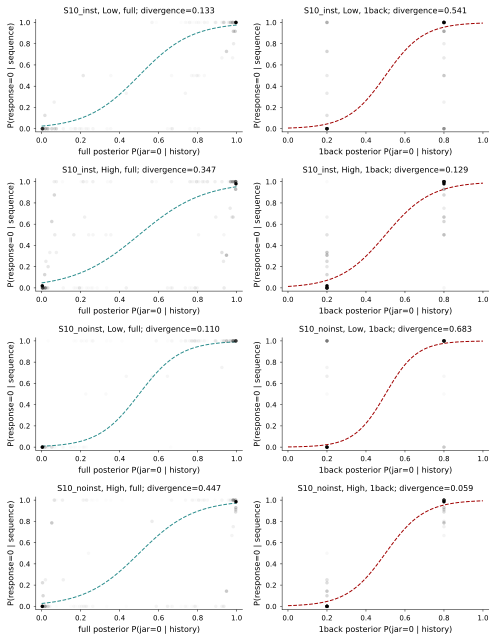

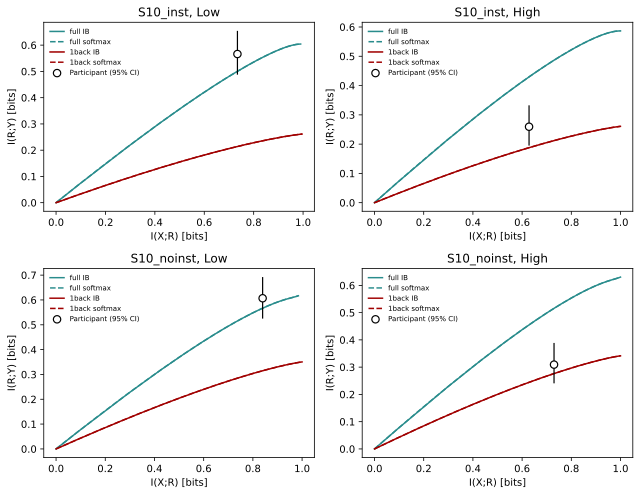

In [60]:
# One observed point per unique seven-bead sequence, even when posterior
# probabilities coincide. Both strategy panels use the SAME history groups.
# Edit this mapping to inspect different participants; defaults match the IB panels.
EXAMPLE_SUBJECTS = {study: alldata.loc[alldata.Study==study,'Subject'].iloc[0]
                    for study in ['HMM_inst','HMM_noinst']}
psych_rows=[]
for key,s in sessions.items():
    trial_table=pd.DataFrame({'X':s['enc'],'response0':1-s['R']})
    observed=trial_table.groupby('X',sort=True).agg(
        choice_prob=('response0','mean'),Ntrials=('response0','size')).reset_index()
    unique_enc,first=np.unique(s['enc'],return_index=True)
    unique_histories=s['X'][first]
    assert np.array_equal(observed.X.to_numpy(),unique_enc)
    for label in ['full','1back']:
        histories=unique_histories if label=='full' else unique_histories[:,-1:]
        posterior=utils.P_jar_g_beads(histories,E,transition(STAY[key[2]]),P0)[:,0]
        frame=observed.copy()
        frame['posterior_prob']=posterior
        frame['strategy']=label
        frame['bead_sequence']=[''.join(map(str,x)) for x in unique_histories]
        for name,value in zip(KEYS,key): frame[name]=value
        psych_rows.append(frame)
psych_summary=pd.concat(psych_rows,ignore_index=True)
psych_summary.to_csv(OUT/'psychometric_summary.csv',index=False)
assert not psych_summary.duplicated(KEYS+['strategy','X']).any()
assert (psych_summary.groupby(KEYS+['strategy']).Ntrials.sum()==493).all()

fig,axes=plt.subplots(4,2,figsize=(7,9),dpi=200)
example_measures=alldata.set_index(KEYS)
for i,(study,subject) in enumerate(EXAMPLE_SUBJECTS.items()):
    for hindex,hazard in enumerate(['Low','High']):
        key=(study,subject,hazard)
        measure_row=example_measures.loc[key]
        for j,(label,color) in enumerate([('full',COLORS['full']),('1back',COLORS['1back'])]):
            ax=axes[2*i+hindex,j]
            data=psych_summary[(psych_summary.Study==study)&(psych_summary.Subject==subject)
                 &(psych_summary.Session==hazard)&(psych_summary.strategy==label)]
            # Recover beta* grid (cached softmax summaries store only information).
            curve=dict(bounds[key][label+'_softmax'],
                       betastar=np.linspace(50/N_B_SOFTMAX,50,N_B_SOFTMAX))
            # Reference methodology: predict beta* from measured complexity;
            # plot empirical choices by sequence, with opacity ∝ sequence count.
            utils.get_IB_predicted_psychometric_plot(measure_row.Ixr,curve,color,ax)
            utils.get_sj_psychometric_plot(data,data[['X','posterior_prob']],ax)
            with np.errstate(divide='ignore',invalid='ignore'):
                divergence=utils.get_psychometric_DKL(data,data[['X','posterior_prob']],
                                                      measure_row.Ixr,curve)
            ax.set(xlim=(-.03,1.03),ylim=(-.03,1.03),
                   xlabel=f'{label} posterior P(jar=0 | history)',
                   ylabel='P(response=0 | sequence)')
            ax.set_title(f'{subject}, {hazard}, {label}; divergence={divergence:.3f}',fontsize=8)
            format_change_axis(ax)
savefig(fig,'psychometrics')

fig,axes=plt.subplots(2,2,figsize=(9,7),dpi=200)
for i,(study,subject) in enumerate(EXAMPLE_SUBJECTS.items()):
    for j,hazard in enumerate(['Low','High']):
        key=(study,subject,hazard);ax=axes[i,j]
        for label,color in [('full',COLORS['full']),('1back',COLORS['1back'])]:
            bound=bounds[key][label];curve=bounds[key][label+'_softmax']
            ax.plot(bound['I_XR'],bound['I_RY'],color=color,label=label+' IB')
            ax.plot(curve['I_XR'],curve['I_RY'],'--',color=color,label=label+' softmax')
        row=example_measures.loc[key]
        # Draw the exact bootstrap limits even if the estimate lies outside them.
        ax.vlines(row.Ixr,row.Iry_CI_lower,row.Iry_CI_upper,
                  color='black',linewidth=1.2,zorder=5)
        ax.scatter([row.Ixr],[row.Iry],s=55,marker='o',facecolor='white',
                   edgecolor='black',linewidth=1.2,zorder=6,label='Participant (95% CI)')
        ax.set(title=f'{subject}, {hazard}',xlabel='I(X;R) [bits]',ylabel='I(R;Y) [bits]')
        ax.legend(fontsize=7,frameon=False)
savefig(fig,'example_softmax_vs_IB')


## Efficiency versus subjective hazard

Analogous to the reference efficiency-versus-parameter analysis: sweep subjective stay probability, generate softmax curves over β*, interpolate each curve at each included participant's measured complexity, divide by that participant's full empirical bound, then average within instruction group and true hazard. These curves use all included participants' actual sequences. The horizontal line at one denotes the full bound; ratios are not clipped. The β* sweep uses the reference 0–50 range; increase its resolution for detailed parameter studies. Black vertical lines indicate the true hazard.

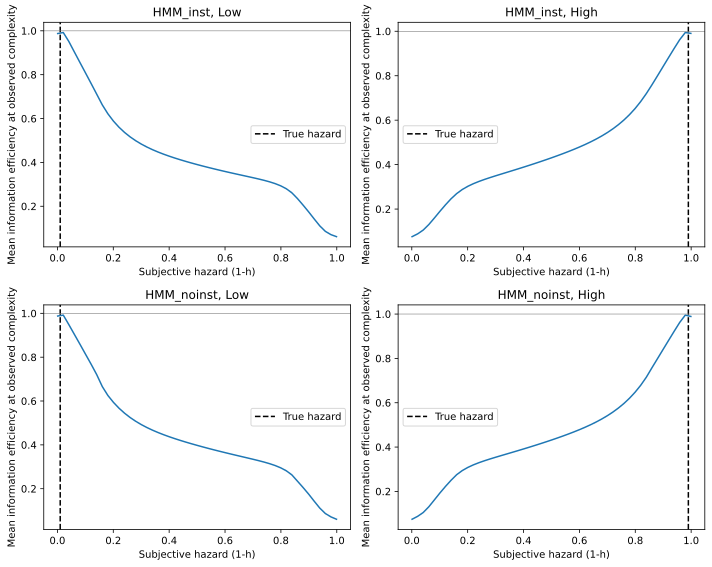

In [61]:
H_GRID = np.linspace(0.001,0.999,5 if SMOKE else 51)
B_GRID = np.linspace(0,50,10 if SMOKE else 300)

def sensitivity_for_session(key,s,ix):
    Xset=utils.get_beads_Xset(WSIZE)
    denom=np.interp(ix,bounds[key]['full']['I_XR'],bounds[key]['full']['I_RY'])
    values=[]
    for h in H_GRID:
        post=utils.P_jar_g_beads(Xset,E,transition(h),P0)
        policies=softmax(B_GRID[:,None,None]*post[None,:,:],axis=2)
        c=empirical_curve(policies,s['X'],s['Y'],Xset)
        order=np.argsort(c['I_XR'])
        values.append(np.interp(ix,c['I_XR'][order],c['I_RY'][order])/denom
                      if denom>1e-12 else np.nan)
    return np.array(values)

sensitivity=[]
for key,s in sessions.items():
    row=alldata.set_index(KEYS).loc[key]
    if row.Ixr < THRESHOLD: continue
    values=cached('sensitivity',(key,s,float(row.Ixr),H_GRID,B_GRID),
        lambda key=key,s=s,ix=row.Ixr:sensitivity_for_session(key,s,ix))
    sensitivity.append(pd.DataFrame(dict(Study=key[0],Subject=key[1],Session=key[2],
        subjective_hazard=1-H_GRID,efficiency=values)))
if sensitivity:
    sensitivity=pd.concat(sensitivity,ignore_index=True)
    sensitivity.to_csv(OUT/'efficiency_parameter_sweep.csv',index=False)
    fig,axes=plt.subplots(2,2,figsize=(10,8))
    for i,study in enumerate(['HMM_inst','HMM_noinst']):
        for j,hazard in enumerate(['Low','High']):
            d=sensitivity[(sensitivity.Study==study)&(sensitivity.Session==hazard)]
            curve=d.groupby('subjective_hazard').efficiency.mean()
            axes[i,j].plot(curve.index,curve.values)
            axes[i,j].axvline(1-STAY[hazard],color='black',ls='--',label='True hazard')
            axes[i,j].axhline(1,color='gray',lw=.6)
            axes[i,j].set(title=f'{study}, {hazard}',xlabel='Subjective hazard (1-h)',
                          ylabel='Mean information efficiency at observed complexity')
            axes[i,j].legend()
    savefig(fig,'efficiency_vs_subjective_hazard')


## Exploratory instruction-group contrasts and reproducibility

Instruction groups are independent; hazard contrasts are paired. Between-group Mann–Whitney tests below compare participant changes, with Holm adjustment across the three IB measures. These are exploratory and do not establish causal instruction effects. Spearman correlations describe fitted β* versus complexity and subjective stay probability versus efficiency. Interpret them alongside convergence diagnostics and the selected sample.

Caches are local trusted pickle files; delete the output cache to force recomputation. Full and smoke results use separate directories. Figures are exported as SVG and analysis tables as CSV. The manifest records data hashes, configuration, and package versions.

In [62]:
contrasts=[]
for metric in ['Ixr','Iry','info_efficiency']:
    c=changes[changes.include_both if metric=='info_efficiency' else changes.include_any]
    a=c.loc['HMM_inst','delta_'+metric].dropna();b=c.loc['HMM_noinst','delta_'+metric].dropna()
    test=mannwhitneyu(a,b,alternative='two-sided') if len(a) and len(b) else None
    contrasts.append(dict(metric=metric,n_inst=len(a),n_noinst=len(b),
        median_inst=a.median(),median_noinst=b.median(),p_value=test.pvalue if test else np.nan))
contrasts=pd.DataFrame(contrasts);contrasts['p_holm']=holm(contrasts.p_value)
contrasts.to_csv(OUT/'instruction_group_change_tests.csv',index=False);display(contrasts)
corr=[]
for (study,hazard),d in alldata[~alldata.below_threshold].groupby(['Study','Session']):
    for x,y in [('best_model_betastar','Ixr'),('fullparam_h','info_efficiency')]:
        g=d[[x,y]].dropna()
        r=spearmanr(g[x],g[y]) if len(g)>2 else None
        corr.append(dict(Study=study,Session=hazard,x=x,y=y,n=len(g),
            rho=r.statistic if r else np.nan,p_value=r.pvalue if r else np.nan))
pd.DataFrame(corr).to_csv(OUT/'exploratory_correlations.csv',index=False)
import importlib.metadata, platform
manifest=dict(helper_sha256=hashlib.sha256((DATA/'filipowicz_analysis_helpers.py').read_bytes()).hexdigest(), config=CONFIG,smoke=SMOKE,python=platform.python_version(),
    data={p.name:hashlib.sha256(p.read_bytes()).hexdigest()
          for p in [DATA/'HMM_inst_beads_finaldat_long.csv',DATA/'HMM_noinst_beads_finaldat_long.csv']},
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','matplotlib','ndd']})
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
print('Results:', OUT)


,metric,n_inst,n_noinst,median_inst,median_noinst,p_value,p_holm
0,Ixr,58,74,-0.159332,-0.163746,0.874312,1.0
1,Iry,58,74,-0.074875,-0.082513,0.946993,1.0
2,info_efficiency,43,54,-0.191536,-0.126259,0.634312,1.0


Results: /workspaces/behavioral_data_reanalyses_IB/Filipowicz_beads/complete_analysis_results
